# 08 · Surfer detection: surfer-only and scene-only clips

A person detector (YOLO26, COCO weights) finds the surfer in the 16 frames of each clip. The boxes are merged into one fixed square region per clip, which yields two complementary versions of the clip:
- **surfer-only**: frames cut to the region (pose and the surfer's own motion, little scene);
- **scene-only**: the region painted gray (wave, water, camera motion, no surfer).

The region is fixed over the clip so the surfer's movement through it is preserved. Both versions are encoded with the same frozen V-JEPA 2 encoder and cached, to compare them with the full frame in the next notebook.

## 1. Setup

In [1]:
import sys
import time
from pathlib import Path

# Make the project root importable (notebooks/ is one level below it)
PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch                      # imported before ultralytics so it is fully initialized first
from ultralytics import YOLO

from src.data.inventory import DATA_DIR
from src.data.surfer import crop_surfer, detect_surfer, mask_surfer, surfer_region
from src.data.video import read_clip

splits = pd.read_csv(PROJECT_ROOT / "data" / "splits.csv")

# Small YOLO26 model with COCO weights (already downloaded to notebooks/)
detector = YOLO("yolo26s.pt")
print(len(splits), "clips | torch", torch.__version__, "| detector loaded on", detector.device)

1056 clips | torch 2.11.0+cu128 | detector loaded on cpu


## 2. Detection on a few clips

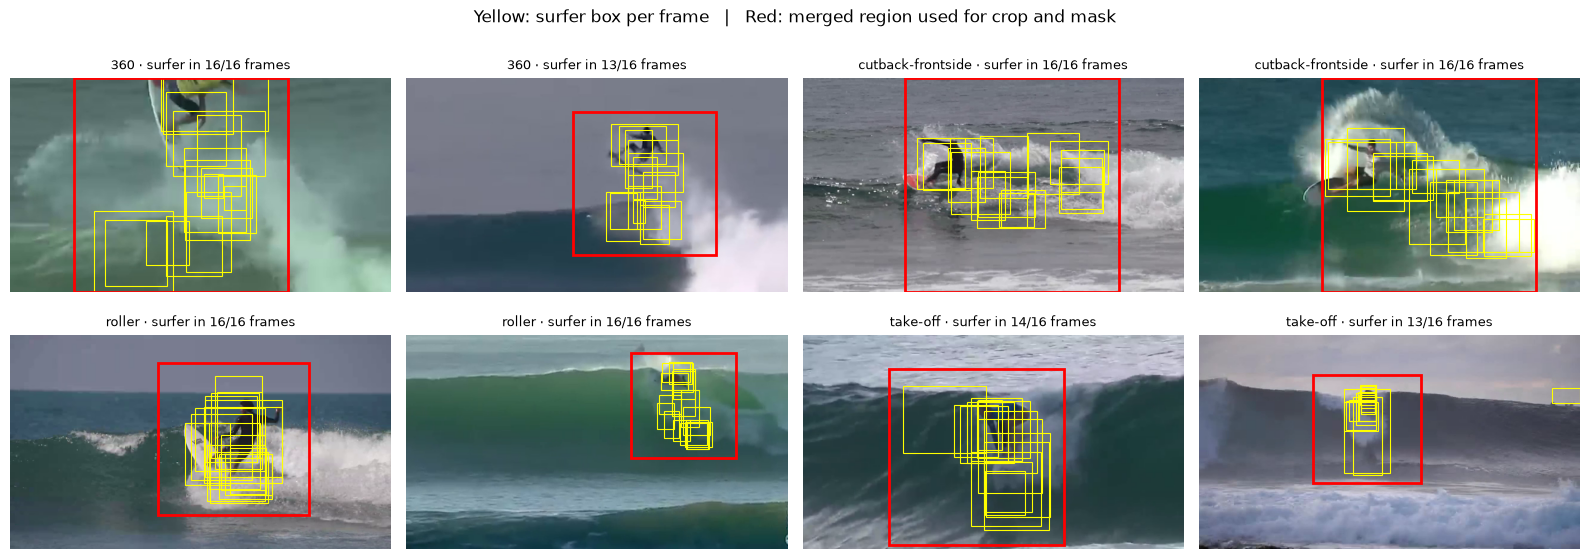

In [2]:
# Two random clips per class: all 16 surfer boxes on the middle frame, plus the merged region
sample = splits.groupby("maneuver").sample(2, random_state=1)

fig, axes = plt.subplots(2, 4, figsize=(16, 6), squeeze=False)
for ax, (_, clip) in zip(axes.flat, sample.iterrows()):
    frames = read_clip(DATA_DIR / clip["clip"])
    boxes = detect_surfer(frames, detector)
    region = surfer_region(boxes, frames.shape[1:])

    ax.imshow(frames[8])
    for x1, y1, x2, y2 in boxes[~np.isnan(boxes).any(axis=1)]:
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color="yellow", lw=0.8))
    if region is not None:
        x1, y1, x2, y2 = region
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color="red", lw=2))
    found = (~np.isnan(boxes).any(axis=1)).sum()
    ax.set_title(f"{clip['maneuver']} · surfer in {found}/16 frames", fontsize=9)
    ax.axis("off")

fig.suptitle("Yellow: surfer box per frame   |   Red: merged region used for crop and mask", fontsize=12)
plt.tight_layout()
plt.show()

## 3. Detection and encoding of all clips

In [3]:
from src.models.encoder import VJEPA2Encoder

encoder = VJEPA2Encoder()

PROCESSED = PROJECT_ROOT / "data" / "processed"
BOXES_FILE = PROCESSED / "surfer_boxes_yolo26s.npz"
FEATURE_FILES = {version: PROCESSED / f"vjepa2_vitl_t8_{version}.npz" for version in ("surfer", "scene")}

def load_cache(path, key):
    """Saved arrays by clip, or an empty dict if nothing was saved yet."""
    if not path.exists():
        return {}
    saved = np.load(path)
    return dict(zip(saved["clips"], saved[key]))

def save_cache(path, cache, key):
    """Save arrays by clip, keeping the clip list next to them (same layout as notebook 03)."""
    if cache:
        clips = list(cache)
        np.savez(path, clips=np.array(clips), **{key: np.stack([cache[c] for c in clips])})

# Resume from a previous partial run, if any
boxes_by_clip = load_cache(BOXES_FILE, "boxes")
features = {version: load_cache(path, "features") for version, path in FEATURE_FILES.items()}
todo = [c for c in splits["clip"] if c not in boxes_by_clip]
print(f"{len(boxes_by_clip)} clips already done, {len(todo)} to go")

start = time.perf_counter()
for k, rel_path in enumerate(todo, 1):
    frames = read_clip(DATA_DIR / rel_path)
    boxes = detect_surfer(frames, detector)
    boxes_by_clip[rel_path] = boxes

    region = surfer_region(boxes, frames.shape[1:])
    if region is not None:   # clips where the surfer is never found get no surfer/scene features
        features["surfer"][rel_path] = encoder(crop_surfer(frames, region))
        features["scene"][rel_path] = encoder(mask_surfer(frames, region))

    if k % 100 == 0 or k == len(todo):
        save_cache(BOXES_FILE, boxes_by_clip, "boxes")
        for version, path in FEATURE_FILES.items():
            save_cache(path, features[version], "features")
        print(f"{len(boxes_by_clip)}/{len(splits)} clips | {time.perf_counter() - start:.0f}s", flush=True)

c:\Users\fabri\Desktop\Portfolio\surf-maneuver-recognition\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1117 23:05:57.529000 49200 .venv\Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.
[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████| 587/587 [00:02<00:00, 270.15it/s]


0 clips already done, 1056 to go
100/1056 clips | 87s
200/1056 clips | 169s
300/1056 clips | 254s
400/1056 clips | 339s
500/1056 clips | 425s
600/1056 clips | 514s
700/1056 clips | 605s
800/1056 clips | 696s
900/1056 clips | 786s
1000/1056 clips | 880s
1056/1056 clips | 927s


## 4. Detection coverage

In [4]:
# Frames per clip where a surfer was found, and clips with usable surfer/scene versions
boxes = np.stack([boxes_by_clip[c] for c in splits["clip"]])           # (1056, 16, 4)
splits["frames_with_surfer"] = (~np.isnan(boxes).any(axis=2)).sum(axis=1)
splits["has_versions"] = splits["clip"].isin(features["surfer"].keys())

coverage = splits.groupby("maneuver").agg(
    clips=("clip", "size"),
    mean_frames_with_surfer=("frames_with_surfer", "mean"),
    clips_under_8_frames=("frames_with_surfer", lambda f: int((f < 8).sum())),
    clips_with_versions=("has_versions", "sum"),
).round(1)
print(coverage)
print(f"\nall classes: surfer found in {(~np.isnan(boxes).any(axis=2)).mean():.1%} of frames, "
      f"{splits['has_versions'].sum()} of {len(splits)} clips usable")

                   clips  mean_frames_with_surfer  clips_under_8_frames  \
maneuver                                                                  
360                  180                     15.1                     0   
cutback-frontside    235                     15.6                     0   
roller               520                     15.6                     1   
take-off             121                     14.8                     4   

                   clips_with_versions  
maneuver                                
360                                180  
cutback-frontside                  235  
roller                             520  
take-off                           121  

all classes: surfer found in 96.5% of frames, 1056 of 1056 clips usable


## 5. Findings

- **Detection works on contest footage.** YOLO26s (COCO weights, class person, confidence 0.25) finds the surfer in 96.5% of the frames, and every one of the 1056 clips gets a surfer region.
- **Take-off is the hardest class to detect**: 14.8 of 16 frames on average and 4 clips with the surfer in fewer than 8 frames, against 15.1 to 15.6 for the other classes. A surfer lying on the board looks less like a person to a COCO detector.
- **Region building needed two safeguards.** A single false detection (another person, an object near the frame border) stretched the merged region, so boxes more than 3 surfer sizes from the clip's medoid center are ignored. The medoid, unlike the median, is always one of the detected boxes, so at least one box is always kept. The margin around the merged boxes is 10%.
- **Cached outputs** (not versioned): `surfer_boxes_yolo26s.npz` with 16 boxes per clip, and `vjepa2_vitl_t8_surfer.npz` / `vjepa2_vitl_t8_scene.npz` with (8, 1024) V-JEPA 2 features for each version.